# Prepare

In [ ]:
try:
    import micropip
    # 'vark' is vendored next to the notebook (top-level package), so
    # we only need to fetch the scientific Python deps via micropip.
    await micropip.install(['pandas', 'matplotlib', 'seaborn', 'scipy'])
except:
    pass  # already installed in standard Python
print("Packages installed")

In [ ]:
from vark import AnthiveClient
from vark import helpers as anthelper
import pandas as pd
import textwrap
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Create client - get current origin from browser
try:
    import js
    api_url = f"{js.location.origin}/api/"
except:
    api_url = None  # Will auto-detect

client = AnthiveClient(api_url)
print(f"✓ Connected to {client.base_url}")

# Select database

In [11]:
anthelper.find_database(client, 'blackb', verbose=True, n=3)

Blackburn2026/seurat_obj_final
  - title  : seurat_obj_final (2026)
  - size   : 73888 cells / 29694 genes
  - layers : counts, data
  - categ  : 16 - SAMPLE, SCT_snn_res.0.2, app_genotype, group_id, ...
  - numer  : 25 - CRM5, DAM6, HLA7, HM8, ...
Blackburn2026/seurat_obj_trisomy_initial
  - title  : seurat_obj_trisomy_initial (2026)
  - size   : 88582 cells / 29694 genes
  - layers : counts
  - categ  : 9 - SAMPLE, app_genotype, group_id, microglia, ...
  - numer  : 5 - human_frac, mouse_frac, nCount_RNA, nFeature_RNA, ...


In [12]:
db_id = 'Blackburn2026/seurat_obj_final'
layer = 'data'

## Find genes of interest

In [27]:
client.search_genes(db_id, q="APOE", limit=50)

['APOE']

In [18]:
client.search_genes(db_id, q="Trem2", limit=50)

['TREM2']

In [19]:
genes = ['APOE', 'TREM2']

## Get expression data

In [28]:
df = client.get_cells(
    db_id,
    genes=genes,
    layer=layer,
    metadata=['SAMPLE', 'group_id'],
    format='dataframe'
)
df.head()

,cell_name,APOE,TREM2,SAMPLE,group_id
0,BDAG185.1D_TCTACTTGTGCAATTC-1,3.210397,2.083004,SAMPLE_1,NLGF_B
1,BDAG185.1D_TCTAGCTTCCCGCATC-1,2.975943,0.806717,SAMPLE_1,NLGF_B
2,BDAG185.1D_TCTAGCTTCCTCTCTC-1,2.737301,2.346120,SAMPLE_1,NLGF_B
3,BDAG185.1D_TCTAGCTTCTAGCGCG-1,3.164668,1.392306,SAMPLE_1,NLGF_B
4,BDAG185.1D_TCTAGCTTCTCACCTG-1,2.757538,2.514029,SAMPLE_1,NLGF_B


In [22]:
df['group_id'].value_counts()

group_id
NLGF_A    26168
hAPP_A    24685
NLGF_B    15826
hAPP_B     7209
Name: count, dtype: int64

## Plot

<Axes: xlabel='group_id', ylabel='APOE'>

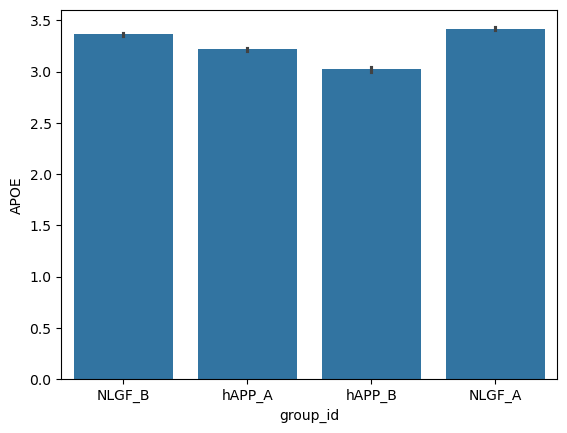

In [29]:
sns.barplot(data=df, x='group_id', y='APOE')

<Axes: xlabel='group_id', ylabel='APOE'>

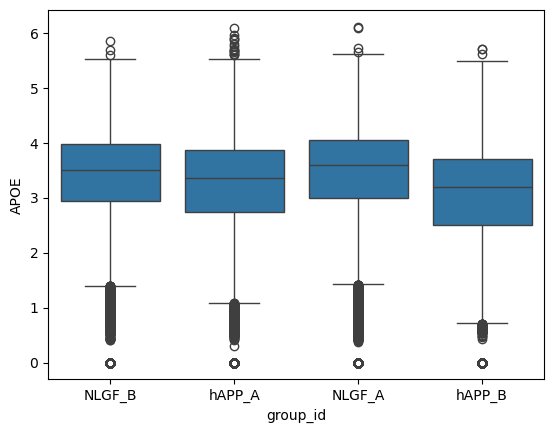

In [25]:
sns.boxplot(data=df, x='group_id', y='APOE')

<Axes: xlabel='APOE', ylabel='Proportion'>

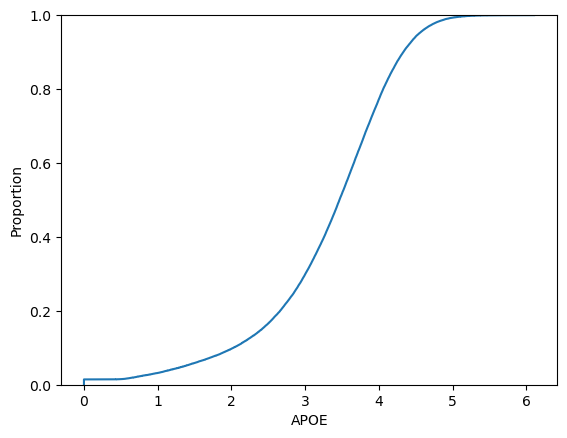

In [33]:
sns.ecdfplot(data=df, x='APOE')